# E12 · Pseudo-labelling round 4: E09a (without AdaBN) as teacher

`E09a` without AdaBN is the best model (**72.67%**, 2026-10-25), better than with AdaBN (71.78%). Round 4 uses it as the
single teacher; everything else is the `E09a` setup (EfficientNet-B0 from ImageNet, 12 bands, `hist_split`, contrast
augmentation, all Kaggle images whose 8 views agree, SeaLake cut to a random 400, used 2× per epoch).

| Variant | Teacher | Teacher's Kaggle score |
|---|---|---|
| E09a (round 3) | E06c + AdaBN | 71.50% |
| **E12a (round 4)** | E09a, no AdaBN | 72.67% |

**Questions:** does a better teacher give a better student (more and cleaner pseudo-labels), and does the student need
AdaBN? Both submission files (with and without AdaBN) are written; since E09a, AdaBN has to be checked every time.

**Train or load.** `LOAD_RUNS` points every variant to its saved run. `None` = train again (about 25 minutes on an M4
GPU; creates new run folders).

## 1 · Setup and data

In [1]:
import json
import sys
from dataclasses import asdict
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src").is_dir())
sys.path.insert(0, str(ROOT))
from src.data import CLASSES, PROJECT_ROOT, TEST_BANDS
from src.experiment import (add_pseudo_labels, class_mix, compare_variants, find_run, finish_run, kaggle_monitor,
                            kaggle_score, load_experiment_data, load_saved_model, plot_class_mix,
                            plot_variant_curves, select_view_agree, teacher_predictions, view_agreement)
from src.models import MEDIUM_TRACK_LIMIT, build_model
from src.plot_style import apply_style
from src.training import Normalizer, TrainConfig, fit, load_run, predict_views
from src.utils import describe_device, get_device, seed_everything

apply_style()

# ---- Experiment settings ---------------------------------------------------------------
NOTEBOOK = "E12_pseudo_labels_r4"
LOAD_RUNS = {   # saved runs; None = train this variant again
    "E12a": "runs/2026-10-25_0052_pl_r4_view_agree_contrast_aug_hist_split_effb0",
}
TEACHER = "pl_r3_view_agree_contrast_aug_hist_split_effb0"      # E09a, no AdaBN, 72.67%
CAPS = {"SeaLake": 400}        # random subset of the agreeing images; other classes: all
REPEAT = 2                     # Kaggle images per epoch, as in E06c
R3_TEACHER = "adabn_balanced_pseudo_label_r2_x2_contrast_aug_hist_split_effb0"   # E06c + AdaBN: round-3 labels
MODEL = "efficientnet_b0"
BANDS = list(TEST_BANDS)
SEED = 42
cfg = TrainConfig(epochs=20, batch_size=128, lr=1e-3, weight_decay=1e-4,
                  label_smoothing=0.1, patience=5, augment=True,
                  photometric={"contrast": (0.9, 1.5), "band_contrast": (0.9, 1.15),
                               "brightness": (0.93, 1.07), "p": 0.8})   # as in E09a
# -----------------------------------------------------------------------------------------

seed_everything(SEED)
device = get_device()              # CUDA > Apple GPU (MPS) > CPU
print("Device:", describe_device(device))
results = {}                        # variant -> RunResult, compared at the end

data = load_experiment_data(BANDS, ["hist_split"], device)
print(data.summary())


def train_or_load(variant, tr_images, tr_labels):
    """Train on EuroSAT + pseudo-labels, or load the saved run."""
    if LOAD_RUNS[variant]:
        model, normalizer, history = load_saved_model(LOAD_RUNS[variant], device)
        return model, normalizer, history, None
    seed_everything(SEED)
    normalizer = Normalizer.fit(data.X_tr)
    model = build_model(MODEL, bands=BANDS, pretrained=True).to(device)
    history, best_state = fit(model, tr_images, tr_labels, data.va_images, data.va_labels,
                              normalizer, cfg, monitor=kaggle_monitor(data, normalizer))
    return model, normalizer, history, best_state


def base_config(variant, run_name, description, pseudo_labels):
    return {"run_name": run_name, "description": description, "notebook": NOTEBOOK, "variant": variant,
            "model": MODEL, "bands": BANDS, "corrections": ["hist_split"], "train": asdict(cfg),
            "split": "split_seed42", "pseudo_labels": pseudo_labels}

Device: Apple GPU (MPS)


train 18,900  val 4,050  internal test 4,050  Kaggle test 4,232


## 2 · Teacher predictions and selection

E09a (no AdaBN) labels every Kaggle image (8 views averaged); all images whose 8 views agree are kept, SeaLake cut to
a random `CAPS`. Compared with the round-3 set (from E06c + AdaBN) that E09a was trained on.

In [2]:
table, teacher_prob = teacher_predictions(TEACHER, data, device)
hard_idx = select_view_agree(table, CAPS, SEED)
r3_table, _ = teacher_predictions(R3_TEACHER, data, device)
r3_idx = select_view_agree(r3_table, CAPS, SEED)
same = np.intersect1d(hard_idx, r3_idx)
print(f"Round 4: {len(hard_idx):,} pseudo-labels (round 3: {len(r3_idx):,}); {len(same):,} images in both, "
      f"of which {(table.loc[same, 'pred'] != r3_table.loc[same, 'pred']).sum()} with a different label")
pd.DataFrame({"teacher predicts": table["pred"].value_counts(),
              "8 views agree": table.loc[table["view_agree"], "pred"].value_counts(),
              "round 4 (E12a)": table.loc[hard_idx, "pred"].value_counts(),
              "round 3 (E09a)": r3_table.loc[r3_idx, "pred"].value_counts(),
              "lowest conf (round 4)": table.loc[hard_idx].groupby("pred")["conf"].min()}).reindex(CLASSES).round(2)

Round 4: 3,211 pseudo-labels (round 3: 2,948); 2,835 images in both, of which 0 with a different label


,teacher predicts,8 views agree,round 4 (E12a),round 3 (E09a),lowest conf (round 4)
pred,,,,,
AnnualCrop,376,317,317,300,0.72
Forest,459,405,405,362,0.63
HerbaceousVegetation,425,367,367,311,0.65
Highway,351,323,323,297,0.62
Industrial,266,233,233,224,0.77
Pasture,282,243,243,216,0.65
PermanentCrop,407,320,320,270,0.66
Residential,399,368,368,341,0.57
River,245,235,235,227,0.56


## 3 · E12a · Round 4

Same training as E09a, only the pseudo-labels differ.

In [3]:
tr_images, tr_labels, _ = add_pseudo_labels(data, table, hard_idx, repeat=REPEAT)
model, normalizer, history, best_state = train_or_load("E12a", tr_images, tr_labels)
results["E12a"] = finish_run(model, normalizer, history, best_state, data, variant="E12a", load_run=LOAD_RUNS["E12a"],
    device=device, seed=SEED, param_limit=MEDIUM_TRACK_LIMIT,
    config=base_config("E12a", "pl_r4_view_agree_contrast_aug_hist_split_effb0",
                       "hist_split + contrast aug + pseudo-labels round 4 (E09a teacher without AdaBN, 8 views agree), 2x",
                       {"teacher": TEACHER, "selection": "view_agree", "caps": CAPS, "repeat": REPEAT,
                        "n_images": int(len(hard_idx))}))
del tr_images, tr_labels

Pseudo-labelled Kaggle images: 3,211 of 4,232, used 2x (25.4% of the training set, 25,322 images)


epoch  1  train loss 1.495 acc 0.589  val loss 0.323 acc 0.924 *  val_conf 0.819  kg_conf 0.703  kg_sealake 0.240  kg_share_AnnualCrop 0.089  kg_share_Forest 0.143  kg_share_HerbaceousVegetation 0.082  kg_share_Highway 0.088  kg_share_Industrial 0.064  kg_share_Pasture 0.065  kg_share_PermanentCrop 0.096  kg_share_Residential 0.082  kg_share_River 0.050  kg_share_SeaLake 0.240  (67s)


epoch  2  train loss 0.738 acc 0.908  val loss 0.209 acc 0.959 *  val_conf 0.872  kg_conf 0.805  kg_sealake 0.238  kg_share_AnnualCrop 0.102  kg_share_Forest 0.125  kg_share_HerbaceousVegetation 0.092  kg_share_Highway 0.079  kg_share_Industrial 0.066  kg_share_Pasture 0.062  kg_share_PermanentCrop 0.087  kg_share_Residential 0.091  kg_share_River 0.058  kg_share_SeaLake 0.238  (65s)


epoch  3  train loss 0.658 acc 0.938  val loss 0.215 acc 0.961 *  val_conf 0.864  kg_conf 0.817  kg_sealake 0.244  kg_share_AnnualCrop 0.092  kg_share_Forest 0.138  kg_share_HerbaceousVegetation 0.084  kg_share_Highway 0.085  kg_share_Industrial 0.064  kg_share_Pasture 0.075  kg_share_PermanentCrop 0.080  kg_share_Residential 0.085  kg_share_River 0.053  kg_share_SeaLake 0.244  (64s)


epoch  4  train loss 0.616 acc 0.957  val loss 0.175 acc 0.970 *  val_conf 0.887  kg_conf 0.847  kg_sealake 0.242  kg_share_AnnualCrop 0.072  kg_share_Forest 0.113  kg_share_HerbaceousVegetation 0.101  kg_share_Highway 0.087  kg_share_Industrial 0.063  kg_share_Pasture 0.073  kg_share_PermanentCrop 0.100  kg_share_Residential 0.092  kg_share_River 0.058  kg_share_SeaLake 0.242  (64s)


...

epoch 11  train loss 0.538 acc 0.987  val loss 0.158 acc 0.979    val_conf 0.895  kg_conf 0.879  kg_sealake 0.240  kg_share_AnnualCrop 0.091  kg_share_Forest 0.123  kg_share_HerbaceousVegetation 0.094  kg_share_Highway 0.085  kg_share_Industrial 0.057  kg_share_Pasture 0.069  kg_share_PermanentCrop 0.093  kg_share_Residential 0.094  kg_share_River 0.054  kg_share_SeaLake 0.240  (68s)


epoch 12  train loss 0.534 acc 0.989  val loss 0.147 acc 0.979    val_conf 0.898  kg_conf 0.890  kg_sealake 0.241  kg_share_AnnualCrop 0.089  kg_share_Forest 0.110  kg_share_HerbaceousVegetation 0.099  kg_share_Highway 0.081  kg_share_Industrial 0.061  kg_share_Pasture 0.072  kg_share_PermanentCrop 0.095  kg_share_Residential 0.095  kg_share_River 0.056  kg_share_SeaLake 0.241  (68s)


epoch 13  train loss 0.526 acc 0.992  val loss 0.149 acc 0.982    val_conf 0.895  kg_conf 0.882  kg_sealake 0.240  kg_share_AnnualCrop 0.083  kg_share_Forest 0.108  kg_share_HerbaceousVegetation 0.104  kg_share_Highway 0.085  kg_share_Industrial 0.064  kg_share_Pasture 0.065  kg_share_PermanentCrop 0.099  kg_share_Residential 0.093  kg_share_River 0.059  kg_share_SeaLake 0.240  (69s)


epoch 14  train loss 0.521 acc 0.994  val loss 0.143 acc 0.983    val_conf 0.899  kg_conf 0.891  kg_sealake 0.241  kg_share_AnnualCrop 0.087  kg_share_Forest 0.108  kg_share_HerbaceousVegetation 0.101  kg_share_Highway 0.081  kg_share_Industrial 0.062  kg_share_Pasture 0.073  kg_share_PermanentCrop 0.096  kg_share_Residential 0.093  kg_share_River 0.059  kg_share_SeaLake 0.241  (69s)
Early stop: no improvement for 5 epochs.


E12a: internal test 98.32% · Kaggle confidence 87.1% (with AdaBN 85.4%) · 4,022,950 parameters
  run folders: runs/2026-10-25_0052_pl_r4_view_agree_contrast_aug_hist_split_effb0, runs/2026-10-25_0053_adabn_balanced_pl_r4_view_agree_contrast_aug_hist_split_effb0


## 4 · Comparison with the teacher (E09a, no AdaBN)

E12a has to beat its teacher. Where do the predictions change: on images the teacher was unsure about or on confident
ones? Both E12a versions (with and without AdaBN) are compared.

In [4]:
ref_dir = find_run(TEACHER)
r_model, r_norm, _ = load_run(ref_dir, device)
ref_views = predict_views(r_model, data.kg_images, r_norm)
ref_prob = ref_views.mean(0)
summary = compare_variants(results, reference=ref_prob, reference_name="E09a")
r_metrics = json.loads((ref_dir / "metrics.json").read_text())
summary.loc["E09a (teacher)"] = {"description": "teacher, no AdaBN", "internal test (%)": r_metrics["internal_test_acc"] * 100,
                                      "confidence (%)": ref_prob.max(1).mean() * 100,
                                      "view agreement (%)": view_agreement(ref_views) * 100,
                                      "same class as E09a (%)": 100.0, "Kaggle public (%)": kaggle_score(ref_dir)}
for k, r in results.items():
    changed = r.kg_prob.argmax(1) != ref_prob.argmax(1)       # without AdaBN, like the teacher
    summary.loc[k, "no AdaBN: same class as E09a (%)"] = (1 - changed.mean()) * 100
    summary.loc[k, "no AdaBN, differs: teacher unsure (%)"] = changed[table["conf"].values < 0.6].mean() * 100
    summary.loc[k, "no AdaBN, differs: teacher confident (%)"] = changed[table["conf"].values >= 0.6].mean() * 100
summary.round(2)

,description,internal test (%),confidence (%),view agreement (%),same class as E09a (%),Kaggle public (%),no AdaBN: same class as E09a (%),"no AdaBN, differs: teacher unsure (%)","no AdaBN, differs: teacher confident (%)"
E12a,hist_split + contrast aug + pseudo-labels roun...,98.320988,85.38472,89.508507,96.053875,None,96.24,45.87,1.2
E09a (teacher),"teacher, no AdaBN",98.864198,87.362061,90.500945,100.0,72.671,NaN,NaN,NaN


In [5]:
# Different predictions: E09a's class (rows) -> E12a's class (no AdaBN) (columns)
ref_pred = np.array(CLASSES)[ref_prob.argmax(1)]
for k, r in results.items():
    new = np.array(CLASSES)[r.kg_prob.argmax(1)]
    changed = new != ref_pred
    print(f"{k}: {changed.sum()} images differ from E09a ({changed.mean():.1%})")
    display(pd.crosstab(ref_pred[changed], new[changed]).rename_axis(index="E09a", columns=k))

E12a: 159 images differ from E09a (3.8%)


E12a,AnnualCrop,Forest,HerbaceousVegetation,Highway,Industrial,Pasture,PermanentCrop,Residential,River,SeaLake
E09a,,,,,,,,,,
AnnualCrop,0,0,2,2,0,5,25,0,0,0
Forest,0,0,22,0,0,6,4,0,1,0
HerbaceousVegetation,0,5,0,1,0,2,1,0,2,0
Highway,0,1,3,0,3,1,3,2,0,0
Industrial,0,0,2,1,0,0,5,6,1,1
Pasture,3,0,3,0,1,0,4,1,0,0
PermanentCrop,5,1,7,0,0,12,0,2,0,0
Residential,0,0,3,0,2,2,0,0,0,0
River,0,0,1,0,1,0,0,0,0,3


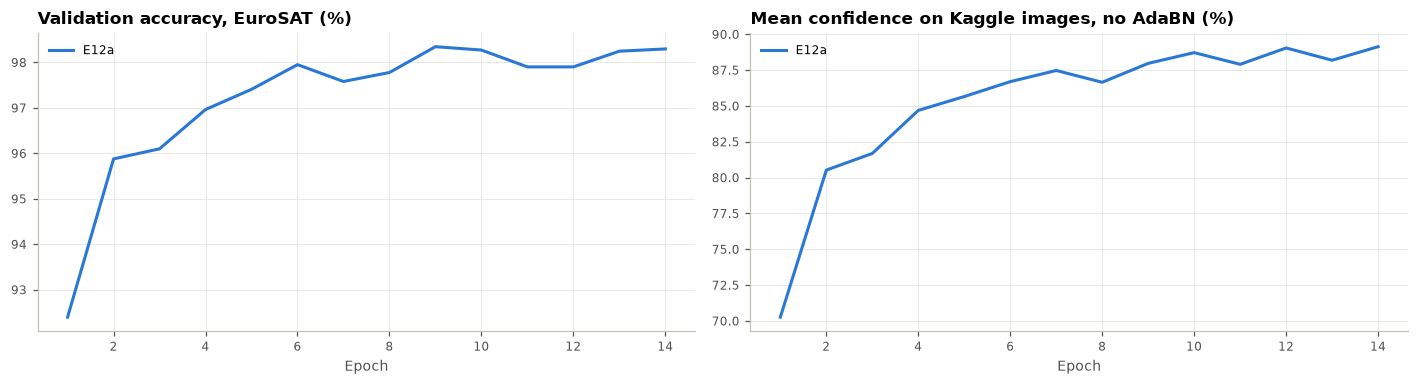

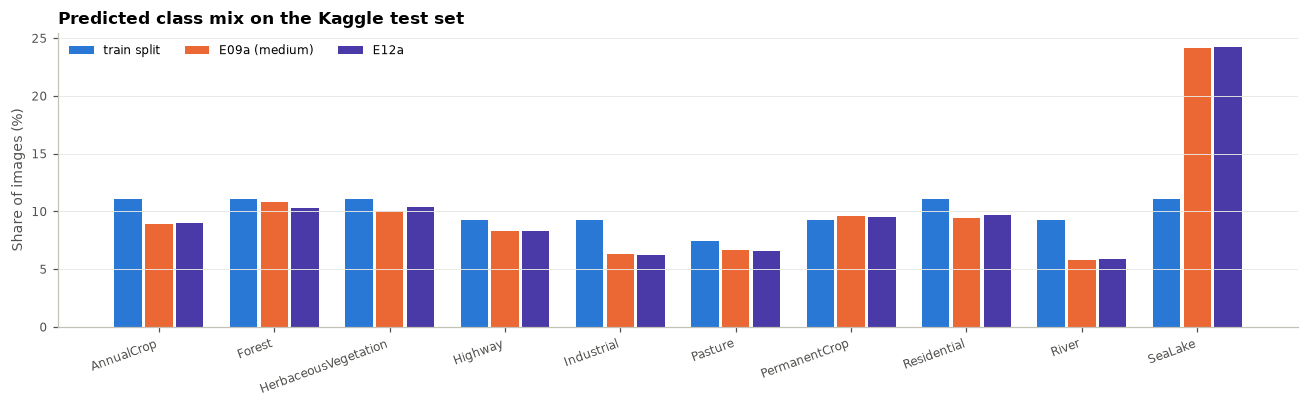

In [6]:
plot_variant_curves(results)
plot_class_mix(pd.DataFrame({"train split": class_mix(np.eye(10)[data.y_tr]), "E09a (medium)": class_mix(ref_prob),
                             **{k: class_mix(r.prob_ada) for k, r in results.items()}}))

## 5 · Conclusion

| Model | Pseudo-labels | Internal test | Kaggle confidence (no AdaBN / AdaBN) | Same class as E09a (no AdaBN) | Kaggle public (no AdaBN / AdaBN) |
|---|---|---|---|---|---|
| E09a (teacher) | 2,948 from E06c + AdaBN | 98.86% | 87.4% / 85.0% | – | **72.67%** / 71.78% |
| E12a | 3,211 from E09a (no AdaBN) | 98.32% | 87.1% / 85.4% | 96.2% | 72.34% / 72.39% |

- **The better teacher gives 9% more pseudo-labels** (3,211 vs 2,948; SeaLake capped at 400 in both), +17 to +50 per
  vegetation class. The 2,835 images in both sets have *identical* labels: E09a has learned round 3 completely, so
  round 4 only adds new images, it corrects none.
- **E12a stopped early** (best epoch 9 of 14) and is 0.5 points lower on the internal test (98.32% vs 98.86%).
- **It changes 3.8% of the Kaggle predictions** (159 images), 45.9% of those the teacher was unsure about and 1.2% of
  the confident ones; mostly AnnualCrop → PermanentCrop (25), Forest → HerbaceousVegetation (22),
  PermanentCrop → Pasture (12): the same pairs as every round.
- **On Kaggle round 4 does not beat its teacher:** 72.34% without AdaBN, 72.39% with (E09a 72.67%), i.e. 6–7 public
  images fewer. AdaBN makes no difference here (+0.05, one image), unlike E09a (−0.89).
- **Pseudo-labelling has saturated.** The student only re-learns what the teacher already believes; the uncertain crop
  and vegetation images stay where the errors are. E09a without AdaBN remains the best model. Further gains need a new
  signal for the vegetation classes, not another round.
